# Análisis exploratorio de los datos de ordeño
## Hecho por: Yael Charles Marin

Se revisan nulos, duplicados, formatos, coherencia, distribuciones, diferencias entre vacas y cuartos, evolución temporal, incidentes y correlaciones. 

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110})
pd.set_option("display.max_columns", 45)
pd.set_option("display.max_rows", 45)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Data" / "dataset_vacas_anonimo.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError("No se encontró Data/dataset_vacas_anonimo.csv desde el directorio actual.")
ruta = raiz / "Data" / "dataset_vacas_anonimo.csv"
df_original = pd.read_csv(ruta, encoding="utf-8")
print(f"Archivo: {ruta.name} | Filas: {len(df_original):,} | Columnas: {df_original.shape[1]}")
display(df_original.head())

Archivo: dataset_vacas_anonimo.csv | Filas: 7,249 | Columnas: 36


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td
0,3d995085,01/03/2025 05:37 a. m.,Ordeño,09:58,23.960,1.000,NaN,NaN,NaN,NaN,1.000,NaN,1.260,1.740,1.860,1.620,0.000,0.000,0.000,0.000,4.920,5.160,5.480,5.210,7063e4b1,NaN,Tanque,NaN,1.740,2.160,2.400,2.100,6.110,5.560,3.330,8.960
1,3d995085,01/03/2025 07:15 p. m.,Ordeño,06:51,17.200,2.000,NaN,DI,NaN,NaN,1.000,NaN,1.140,1.800,2.040,1.740,0.000,0.000,0.000,0.000,4.580,4.840,5.260,4.880,7063e4b1,NaN,Tanque,NaN,2.100,2.340,2.520,2.280,3.230,4.860,2.690,6.420
2,3d995085,02/03/2025 02:24 a. m.,Ordeño,07:23,11.130,1.000,NaN,NaN,NaN,NaN,1.000,TI,1.200,1.440,1.740,1.440,0.000,0.000,0.000,0.000,4.260,4.380,5.000,4.520,7063e4b1,NaN,Tanque,NaN,1.680,1.980,2.340,1.920,4.400,2.430,1.150,3.150
3,3d995085,02/03/2025 07:51 p. m.,Ordeño,08:29,20.640,2.000,NaN,NaN,NaN,NaN,1.000,NaN,1.200,1.680,1.920,1.680,0.000,0.000,0.000,0.000,4.360,4.770,5.010,4.820,7063e4b1,NaN,Tanque,NaN,2.100,2.220,2.520,2.400,5.720,4.880,3.100,6.940
4,3d995085,03/03/2025 06:00 a. m.,Ordeño,05:05,9.590,1.000,NaN,NaN,NaN,NaN,1.000,NaN,1.140,1.620,1.800,1.500,0.000,0.000,0.000,0.000,4.130,4.420,4.360,4.440,7063e4b1,NaN,Tanque,NaN,1.800,2.100,2.280,1.980,2.690,2.410,1.440,3.050


## 1. Inventario y calidad de los datos

La tabla resume tipos, valores disponibles y diversidad de cada columna. Los indicadores de incidentes contienen etiquetas de cuartos y nulos; un campo vacío no se interpreta automáticamente como ausencia de un incidente.

In [3]:
## Tipo de datos, nulos y valores distintos

perfil = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "no_nulos": df_original.notna().sum(),
    "nulos": df_original.isna().sum(),
    "nulos_pct": df_original.isna().mean().mul(100),
    "valores_distintos": df_original.nunique(dropna=True),
})
display(perfil)


,tipo,no_nulos,nulos,nulos_pct,valores_distintos
id_vaca,str,7249,0,0.000,34
main_hora_de_inicio,str,7249,0,0.000,7141
main_accion,str,7249,0,0.000,3
main_duracion_mm_ss,str,7249,0,0.000,803
main_produccion_kg,float64,7016,233,3.214,2120
estado_numero_de_ordeno,float64,7016,233,3.214,5
estado_rcs_1000_celulas_ml,float64,0,7249,100.000,0
estado_patada,str,1299,5950,82.080,15
estado_incompleto,str,1014,6235,86.012,15
estado_pezones_no_encontrados,str,1239,6010,82.908,15


De esta tabla obtenemos ciertas dudas para más adelante, por ejemplo:
- De los 7249 datos para la columna de duración_mm_ss solo 803 son distintos, deberá existir algun patron de la duración del ordeño.
- Existe una sola instancia de razón de la desviación que es no nula, a que se debe esto, se debería analizar esta instancia.

In [4]:
## Estadistica descriptiva de las variables numéricas

display(df_original.select_dtypes(include="number").describe().T)

,count,mean,std,min,25%,50%,75%,max
main_produccion_kg,"7,016.000",13.723,5.331,0.000,9.860,13.260,17.060,39.470
estado_numero_de_ordeno,"7,016.000",1.775,0.813,1.000,1.000,2.000,2.000,5.000
estado_rcs_1000_celulas_ml,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_amd_ubre,"7,016.000",0.150,0.357,0.000,0.000,0.000,0.000,1.000
media_de_los_flujos_kg_min_di,"7,016.000",1.033,0.433,0.000,0.780,1.020,1.320,4.980
media_de_los_flujos_kg_min_dd,"7,013.000",1.106,0.405,0.000,0.840,1.080,1.380,2.640
media_de_los_flujos_kg_min_ti,"6,717.000",1.053,0.494,0.000,0.780,1.080,1.320,4.080
media_de_los_flujos_kg_min_td,"6,952.000",1.069,0.455,0.000,0.840,1.080,1.320,2.820
sangre_ppm_di,"7,016.000",23.163,287.061,0.000,0.000,0.000,0.000,"7,997.000"
sangre_ppm_dd,"7,013.000",8.596,89.218,0.000,0.000,0.000,0.000,"2,786.000"


A primera vista, los datos no presentan distribuciones extremas, ya que su desviación estandar es más pequeña a la media, sin embargo aún no podemos afirmar esto.

Los datos que si saltan a la vista son las de sangre en partes por millon, que en comparación su escala es muy grande, pero lo que representan realmente te das cuenta que es un número muy pequeño, así que deberíamos analizar la distribución y entender que tanto son 8 mil partes por millon.

In [5]:
print("Columnas completamente vacías:", perfil.index[perfil.no_nulos.eq(0)].tolist())

display(df_original["main_accion"].value_counts(dropna=False).rename("eventos").to_frame())

Columnas completamente vacías: ['estado_rcs_1000_celulas_ml', 'misc_usuario']


,eventos
main_accion,
Ordeño,7016
Rechazada,172
Echada sin ordeñar,61


La distribución de los eventos son: 
- ordeño 96.78% de los datos son ordeños normales
- Rechazada 2.37% son vacas rechazadas, esto según la información recolectada al caetec es cuando la vaca ya está en la maquina pero por alguna u otra razón no se ordeña.
- Echada sin ordeñar 0.84% son vacas que ni siquiera llegan a formar parte de la cola o entrar en la maquina de ordeño.


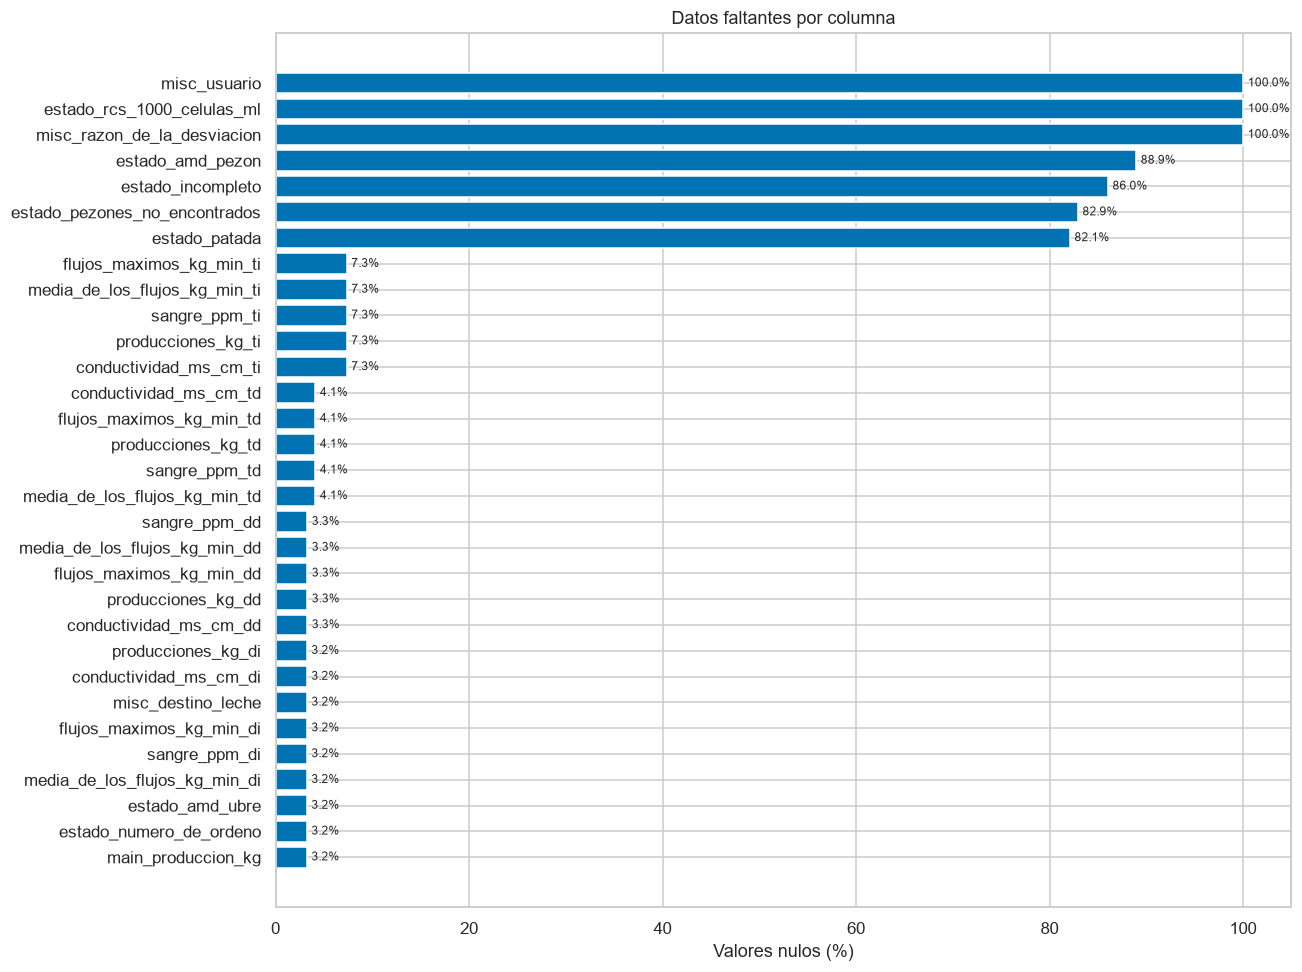

In [6]:
nulos = perfil.loc[perfil.nulos.gt(0)].sort_values("nulos_pct")
fig, ax = plt.subplots(figsize=(12, 9))
ax.barh(nulos.index, nulos.nulos_pct)
ax.set(xlabel="Valores nulos (%)", title="Datos faltantes por columna", xlim=(0, 105))
for i, v in enumerate(nulos.nulos_pct):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

En esta gráfica vemos el porcentaje de datos nulos para cada una de las columnas, las primeras 3 tienen todos sus datos nulos, por lo que no nos aportan informacion de las vacas ya que no sabemos quien operó la maquina en los ordeños, el estado_rcs_1000_celulas_ml nos comunicaron que es una columna que no se generan valores y la razón de la desviación tiene solo 1 dato nulo.

De las columnas que pertenecen a la categoria de estado, se espera que el porcentaje de datos nulos sea alto, pues esto indica que el ordeño procedio correctamente.

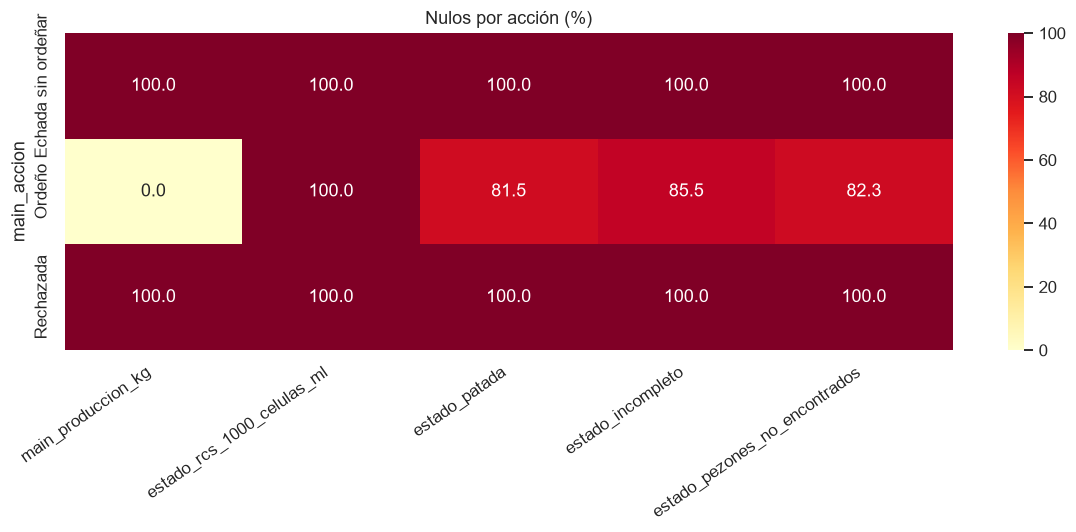

In [7]:
columnas_revision = ["main_produccion_kg", "estado_rcs_1000_celulas_ml",
    "estado_patada", "estado_incompleto", "estado_pezones_no_encontrados"]

nulos_por_accion = df_original.groupby("main_accion")[columnas_revision].agg(
    lambda s: s.isna().mean() * 100)
sns.heatmap(nulos_por_accion, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100)
plt.title("Nulos por acción (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Lo que indica esta tabla es que de las 3 acciones (ordeño, rechazada y echada sin ordeñar) cuales columnas presentan valores nulos, por ejemplo para rechazada y echada sin ordeñar, todas las otras columnas evaluadas son nulas, ya sea por la baja cantidad de registros que tienen estas acciones o por el flujo que realiza la maquina, porque es de esperarse que una vaca que fue rechazada no tenga producción. 

Ahora analizando la acción de ordeño, la producción no tiene datos nulos, el estado de patada el 81.5% son nulos, así que 18.5% de los ordeños presentan patada, el 14.5% son ordeños incompletos y el 13.7% presentan ordeños con pezones no encontrados.

### Duplicados exactos y coincidencias de identificadores

Se distinguen filas idénticas de coincidencias en `(id_vaca, main_hora_de_inicio)`. Una hora registrada al minuto puede agrupar eventos distintos; esas coincidencias requieren revisión y no se eliminan automáticamente. Para las gráficas posteriores solo se excluyen copias exactas, conservando la primera aparición.

In [8]:
clave = ["id_vaca", "main_hora_de_inicio"]
duplicados_exactos = df_original.duplicated()
coincidencias_clave = df_original.duplicated(clave, keep=False)

print(f"Copias exactas adicionales: {duplicados_exactos.sum()}")
print(f"Filas involucradas en duplicados exactos: {df_original.duplicated(keep=False).sum()}")
print(f"Coincidencias adicionales en vaca y hora: {df_original.duplicated(clave).sum()}")

display(df_original.loc[df_original.duplicated(keep=False),
    clave + ["main_accion", "main_duracion_mm_ss", "main_produccion_kg"]])

display(df_original.loc[coincidencias_clave,
    clave + ["main_accion", "main_duracion_mm_ss", "main_produccion_kg"]]
    .sort_values(clave).head(30))

df = df_original.drop_duplicates().copy()
print(f"Base exploratoria después de quitar copias exactas: {len(df):,} eventos")

Copias exactas adicionales: 2
Filas involucradas en duplicados exactos: 4
Coincidencias adicionales en vaca y hora: 25


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg
541,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN
542,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN
3125,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN
3126,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg
3974,0072065b,16/03/2025 05:03 a. m.,Ordeño,11:52,23.580
3975,0072065b,16/03/2025 05:03 a. m.,Echada sin ordeñar,11:51,NaN
4156,0072065b,27/06/2025 12:45 p. m.,Ordeño,06:10,16.020
4157,0072065b,27/06/2025 12:45 p. m.,Echada sin ordeñar,06:09,NaN
1645,07802001,16/03/2025 04:46 a. m.,Ordeño,08:45,26.650
1646,07802001,16/03/2025 04:46 a. m.,Echada sin ordeñar,08:44,NaN
1908,07802001,27/06/2025 01:56 p. m.,Ordeño,05:12,10.200
1909,07802001,27/06/2025 01:56 p. m.,Echada sin ordeñar,05:12,NaN
1030,37248cfd,16/03/2025 03:03 a. m.,Ordeño,06:25,12.160
1031,37248cfd,16/03/2025 03:03 a. m.,Echada sin ordeñar,06:25,NaN


Base exploratoria después de quitar copias exactas: 7,247 eventos


Se encontraron 4 registros exactamente iguales, que corresponden a eventos rechazados de ordeño cuya fecha de inicio coincide exactamente, lo que puede representar un error de la maquina.

La siguiente tabla muestra registros todavia más problemáticos, se trata de pares de valores pertenecientes a la misma vaca que en la mayoría de los casos son eventos cuya acción es ordeño y echada sin ordeñar, las cuales ocurrieron a la misma hora y fecha, las que son de ordeño tienen producción y las echada sin ordeñar no. Se recomienda preguntar al socio formador para obtener más contexto, pero una posible explicación es que la maquina registró el segundo evento como error y se deba eliminar.

## 2. Fechas, duración y validaciones de coherencia

Las fechas se interpretan como **día/mes/año** y las horas usan marcas españolas `a. m.` y `p. m.`. La duración se convierte explícitamente desde `mm:ss` a minutos (no es una hora del día). Las conversiones inválidas se reportan; no se imputan.

In [19]:
hora_texto = (df["main_hora_de_inicio"].astype("string")
    .str.replace(r"a\.\s*m\.", "AM", regex=True)
    .str.replace(r"p\.\s*m\.", "PM", regex=True).str.strip())
df["fecha_hora"] = pd.to_datetime(hora_texto, format="%d/%m/%Y %I:%M %p", errors="coerce")
partes = df["main_duracion_mm_ss"].astype("string").str.extract(r"^(\d+):([0-5]\d)$")
df["duracion_min"] = pd.to_numeric(partes[0], errors="coerce") + pd.to_numeric(partes[1], errors="coerce") / 60
df["fecha"] = df.fecha_hora.dt.normalize()
df["hora"] = df.fecha_hora.dt.hour
df["mes"] = df.fecha_hora.dt.to_period("M").astype("string")

errores_conversion = pd.Series({
    "fechas presentes no interpretables": (df.main_hora_de_inicio.notna() & df.fecha_hora.isna()).sum(),
    "duraciones presentes no interpretables": (df.main_duracion_mm_ss.notna() & df.duracion_min.isna()).sum(),
})

display(errores_conversion.to_frame("filas"))

print(f"Periodo: {df.fecha_hora.min()} a {df.fecha_hora.max()}")
print(f"Vacas: {df.id_vaca.nunique()} | Equipos de ordeño: {df.misc_eo_po.nunique()}")

ordenos = df.loc[df["main_accion"].eq("Ordeño")].copy()

cuartos = ["di", "dd", "ti", "td"]
columnas_cuartos = [f"producciones_kg_{q}" for q in cuartos]
ordenos["suma_cuartos_kg"] = ordenos[columnas_cuartos].sum(axis=1, min_count=4)
ordenos["diferencia_total_kg"] = ordenos.main_produccion_kg - ordenos.suma_cuartos_kg
mediciones = [c for c in df_original.select_dtypes(include="number").columns
              if c.startswith(("main_produccion", "media_de_los_flujos", "sangre_",
                               "conductividad_", "flujos_maximos_", "producciones_"))]
validaciones = pd.Series({
    "ordeños sin producción": ordenos.main_produccion_kg.isna().sum(),
    "ordeños con producción cero": ordenos.main_produccion_kg.eq(0).sum(),
    "ordeños con duración cero": ordenos.duracion_min.eq(0).sum(),
    "filas con alguna medición negativa": df[mediciones].lt(0).any(axis=1).sum(),
    "ordeños con cuatro producciones disponibles": ordenos.suma_cuartos_kg.notna().sum(),
    "diferencia total vs suma > 0.05 kg": ordenos.diferencia_total_kg.abs().gt(0.05 + 1e-9).sum(),
})
display(validaciones.to_frame("filas"))


,filas
fechas presentes no interpretables,0
duraciones presentes no interpretables,0


Periodo: 2025-03-01 00:06:00 a 2025-07-18 10:14:00
Vacas: 34 | Equipos de ordeño: 3


,filas
ordeños sin producción,0
ordeños con producción cero,4
ordeños con duración cero,0
filas con alguna medición negativa,0
ordeños con cuatro producciones disponibles,6650
diferencia total vs suma > 0.05 kg,1


In [21]:
columnas_detalle = clave + ["main_duracion_mm_ss", "main_produccion_kg"] + columnas_cuartos + [
    "suma_cuartos_kg", "diferencia_total_kg", "estado_incompleto",
    "estado_pezones_no_encontrados", "estado_patada", "misc_eo_po"]

print("Detalle de los ordeños con producción total de 0 kg:")
display(ordenos.loc[ordenos.main_produccion_kg.eq(0), columnas_detalle])
print("Detalle de los ordeños que superan la tolerancia mayor a 0.05 kg:")
display(ordenos.loc[ordenos.diferencia_total_kg.abs().gt(0.05 + 1e-9),
    columnas_detalle])

Detalle de los ordeños con producción total de 0 kg:


,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,suma_cuartos_kg,diferencia_total_kg,estado_incompleto,estado_pezones_no_encontrados,estado_patada,misc_eo_po
829,3ce7dd1a,13/04/2025 06:44 p. m.,14:52,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,86696b37
2772,4111103c,17/05/2025 03:33 a. m.,02:57,0.000,0.000,0.000,0.000,0.000,0.000,0.000,"DD,TI,TD",Todos,NaN,86696b37
4972,505279da,16/07/2025 03:20 p. m.,00:55,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,"DI,DD,TI",NaN,7063e4b1
7014,a878349c,03/05/2025 11:29 p. m.,06:39,0.000,0.000,0.000,0.000,0.000,0.000,0.000,Todos,Todos,NaN,86696b37


Detalle de los ordeños que superan la tolerancia mayor a 0.05 kg:


,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,suma_cuartos_kg,diferencia_total_kg,estado_incompleto,estado_pezones_no_encontrados,estado_patada,misc_eo_po
6215,609c6e22,16/06/2025 08:38 a. m.,18:56,8.970,0.000,4.140,3.520,4.760,12.420,-3.450,NaN,DI,NaN,7063e4b1


La primera tabla son los 4 registros que presentaron registros de ordeño pero no producción, se observa además de que el ordeño se debió a que no se encontraron los pezones de la vaca, que tenemos diferentes tipos de valores, para esta columna, ya que puede especificar los cuartos especificos o decir todos, además de que existe un registro como NaN, en estado incompleto.

La siguiente tabla presenta el registro cuya producción es menor a la suma de sus cuartos. Por lo que quizá se trate de algun error de registro de la maquina.

## 3. Distribuciones y valores extremos

Las distribuciones siguientes corresponden exclusivamente a ordeños, después de excluir duplicados exactos. Se señalan valores extremos con la regla exploratoria de **1.5 × IQR**, sin borrarlos: pueden corresponder a variación real, fallas de medición o eventos que necesitan contexto.

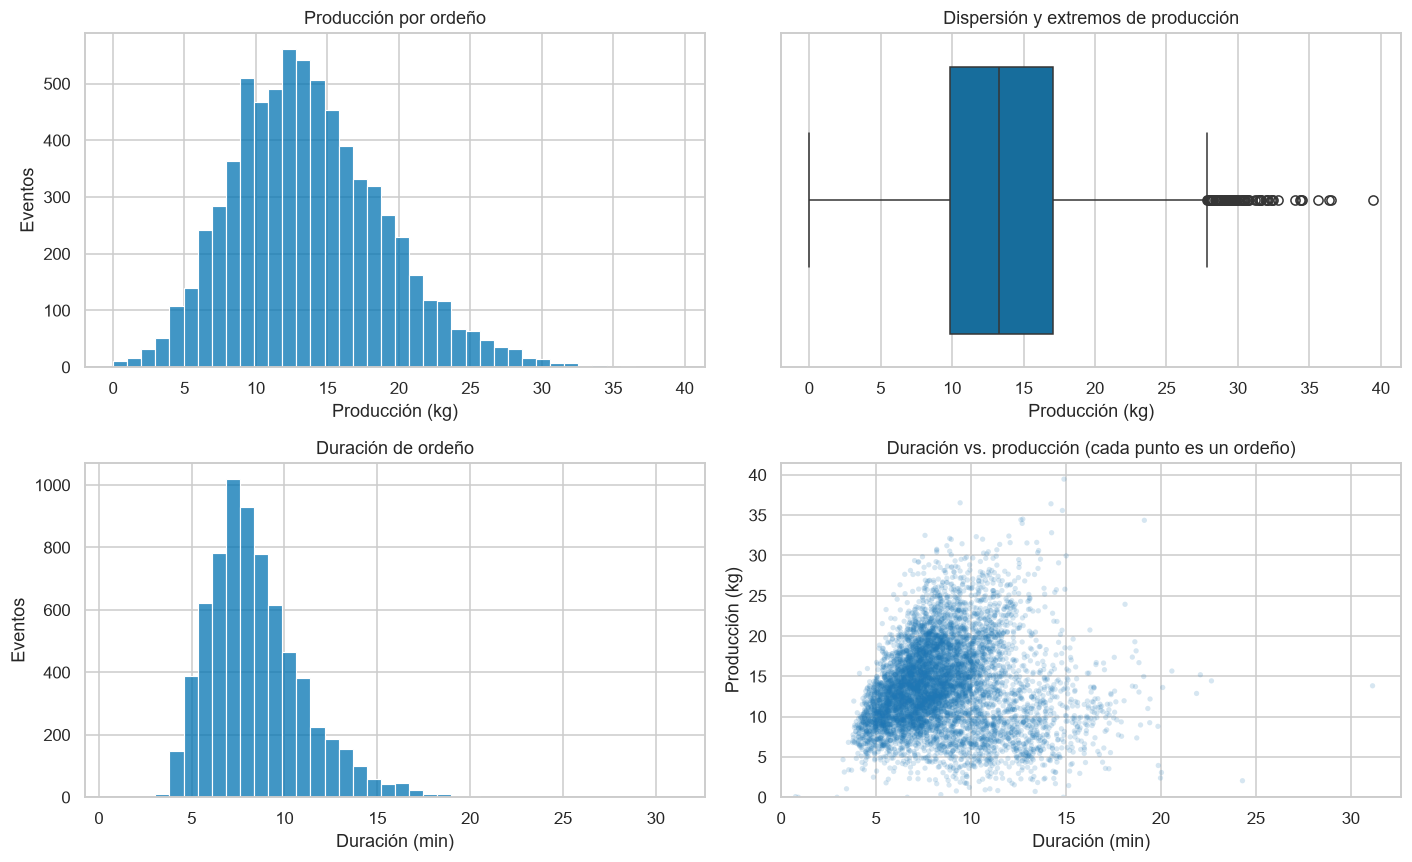

,variable,n,limite_inferior,limite_superior,extremos,extremos_pct,observacion
0,main_produccion_kg,7016,-0.940,27.860,78,1.112,Revisión exploratoria
1,duracion_min,7016,1.983,14.517,206,2.936,Revisión exploratoria
2,sangre_ppm_di,7016,0.000,0.000,118,1.682,IQR = 0: regla poco informativa
3,sangre_ppm_dd,7013,0.000,0.000,100,1.426,IQR = 0: regla poco informativa
4,sangre_ppm_ti,6717,0.000,0.000,150,2.233,IQR = 0: regla poco informativa
5,sangre_ppm_td,6952,0.000,0.000,63,0.906,IQR = 0: regla poco informativa


In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(data=ordenos, x="main_produccion_kg", bins=40, ax=axes[0, 0])
axes[0, 0].set(title="Producción por ordeño", xlabel="Producción (kg)", ylabel="Eventos")
sns.boxplot(data=ordenos, x="main_produccion_kg", ax=axes[0, 1])
axes[0, 1].set(title="Dispersión y extremos de producción", xlabel="Producción (kg)")
sns.histplot(data=ordenos, x="duracion_min", bins=40, ax=axes[1, 0])
axes[1, 0].set(title="Duración de ordeño", xlabel="Duración (min)", ylabel="Eventos")
axes[1, 1].scatter(ordenos.duracion_min, ordenos.main_produccion_kg,
                   s=12, alpha=0.18, color="tab:blue", edgecolors="none")
axes[1, 1].set(title="Duración vs. producción (cada punto es un ordeño)",
               xlabel="Duración (min)", ylabel="Producción (kg)")
axes[1, 1].set(xlim=(0, None), ylim=(0, None))
plt.tight_layout()
plt.show()

filas_iqr = []
for c in ["main_produccion_kg", "duracion_min"] + [f"sangre_ppm_{q}" for q in cuartos]:
    s = ordenos[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    extremos = (s.lt(inferior) | s.gt(superior)).sum()
    filas_iqr.append([c, len(s), inferior, superior, extremos, extremos / len(s) * 100,
                      "IQR = 0: regla poco informativa" if iqr == 0 else "Revisión exploratoria"])
display(pd.DataFrame(filas_iqr, columns=["variable", "n", "limite_inferior", "limite_superior",
                                        "extremos", "extremos_pct", "observacion"]))

La gráfica superior izquierda es la distribución de la producción a lo largo de todo el dataset, se puede observar que la mayoría de eventos caen en los 13 kg de producción (es esperado por su media) los eventos tienen un rango de entre 0 y 40 kg de producción aproximadamente y su distribución es parecida a una normal, pero se aprecia una pequeña cola hacia la derecha. 

Con la grafica superior a la derecha, podemos observar que el 50% de los datos de producción de las vacas está entre los 10 y 15 kg de producción y los puntos que aparecen se consideran valores atipicos de producción, en este caso corresponden a una producción mayor, siendo el mayor cercano a 40 kg de producción.

Con la gráfica inferior izquierda se observa la distribución de la duración del ordeño y este tiene una cola más marcada hacia la derecha, por unos cuantos valores extremos cercanos a los 30 minutos. La mayoría de valores recae entre los 8 minutos aproximadamente.

La grafica inferior derecha se muestran los datos de producción en kg y la duración de la extraccion de leche, se observa un cierto patron en los datos, pero no un comportamiento lineal claro, posteriormente con un analisis de correlación podemos ver más claramente esto, y también identificamos ciertos valores atipicos como un ordeño con duración cercana a los 30 minutos y varios alrededor de 20 minutos.

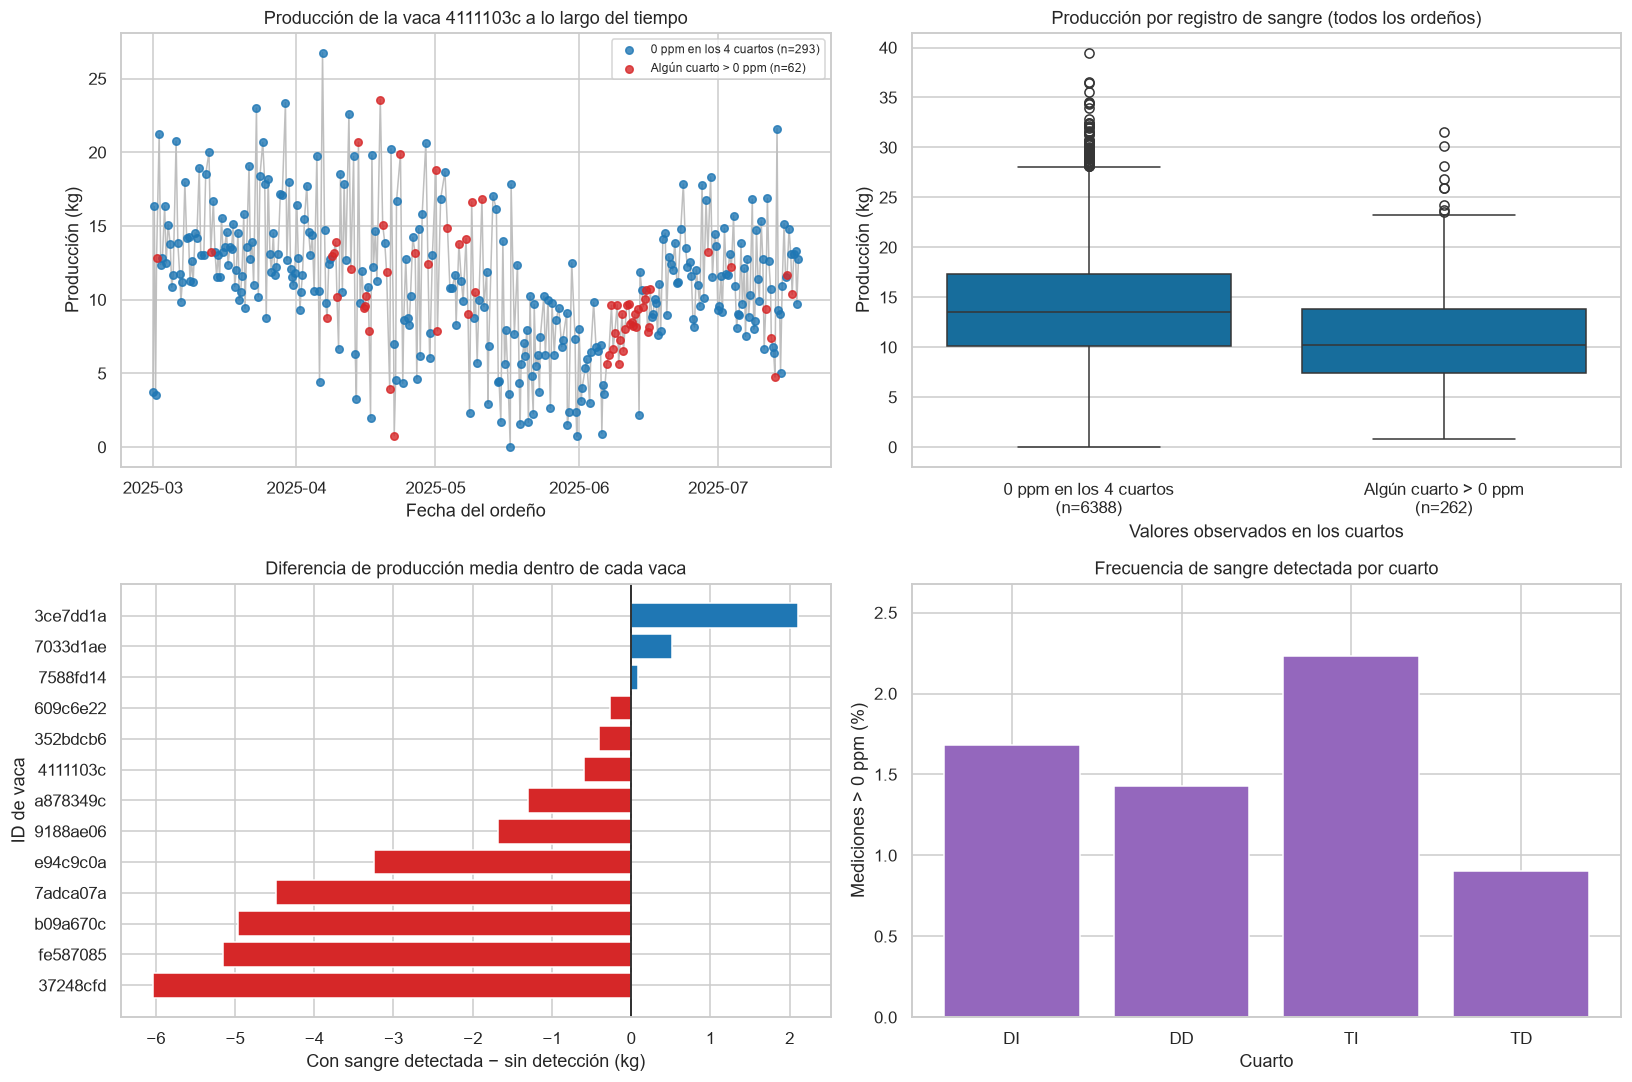

Comparación de 6,650 ordeños con cuatro mediciones; 366 excluidos por mediciones faltantes.
Comparación dentro de vaca: 13 vacas con al menos 5 ordeños con detección y 20 sin detección.
Las diferencias son descriptivas: un valor > 0 ppm es una medición del sensor, no un diagnóstico ni prueba de causalidad.


In [ ]:
# Para comparar grupos, usamos solo ordeños con mediciones en los cuatro cuartos.
columnas_sangre = [f"sangre_ppm_{q}" for q in cuartos]
sangre = ordenos.loc[ordenos[columnas_sangre].notna().all(axis=1)].copy()
sangre["sangre_detectada"] = sangre[columnas_sangre].gt(0).any(axis=1)
sangre["grupo_sangre"] = sangre["sangre_detectada"].map({False: "0 ppm en los 4 cuartos", True: "Algún cuarto > 0 ppm"})
conteos_sangre = sangre["grupo_sangre"].value_counts()

# Elegimos la vaca con más ordeños con sangre detectada y al menos 20 sin detección.
conteos_vaca = sangre.groupby(["id_vaca", "sangre_detectada"]).size().unstack(fill_value=0)
vacas_ejemplo = conteos_vaca.loc[conteos_vaca[False].ge(20) & conteos_vaca[True].gt(0)]
id_ejemplo = vacas_ejemplo[True].idxmax()
serie_vaca = sangre.loc[sangre.id_vaca.eq(id_ejemplo)].sort_values("fecha_hora")

# Diferencia de producción media entre ambos tipos de ordeño, dentro de cada vaca.
medias_vaca = sangre.groupby(["id_vaca", "sangre_detectada"])["main_produccion_kg"].agg(["mean", "size"]).unstack()
vacas_comparables = medias_vaca.loc[(medias_vaca[("size", True)] >= 5) & (medias_vaca[("size", False)] >= 20)]
diferencia_vaca = (vacas_comparables[("mean", True)] - vacas_comparables[("mean", False)]).sort_values()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ax = axes[0, 0]
ax.plot(serie_vaca.fecha_hora, serie_vaca.main_produccion_kg, color="0.75", linewidth=1)
for detectada, color, etiqueta in [(False, "tab:blue", "0 ppm en los 4 cuartos"),
                                    (True, "tab:red", "Algún cuarto > 0 ppm")]:
    puntos = serie_vaca.loc[serie_vaca.sangre_detectada.eq(detectada)]
    ax.scatter(puntos.fecha_hora, puntos.main_produccion_kg, s=24, alpha=0.8,
               color=color, label=f"{etiqueta} (n={len(puntos)})", zorder=3)
ax.set(title=f"Producción de la vaca {id_ejemplo} a lo largo del tiempo",
       xlabel="Fecha del ordeño", ylabel="Producción (kg)")
ax.legend(fontsize=8)

ax = axes[0, 1]
orden_grupos = ["0 ppm en los 4 cuartos", "Algún cuarto > 0 ppm"]
sns.boxplot(data=sangre, x="grupo_sangre", y="main_produccion_kg",
            order=orden_grupos, ax=ax)
ax.set(title="Producción por registro de sangre (todos los ordeños)",
       xlabel="Valores observados en los cuartos", ylabel="Producción (kg)")
ax.set_xticks(range(2), [f"{g}\n(n={conteos_sangre[g]})" for g in orden_grupos])

ax = axes[1, 0]
ax.barh(diferencia_vaca.index, diferencia_vaca.values,
        color=["tab:red" if v < 0 else "tab:blue" for v in diferencia_vaca.values])
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Diferencia de producción media dentro de cada vaca",
       xlabel="Con sangre detectada − sin detección (kg)", ylabel="ID de vaca")

ax = axes[1, 1]
tasas_cuarto = ordenos[columnas_sangre].gt(0).sum().div(ordenos[columnas_sangre].notna().sum()).mul(100)
ax.bar([q.upper() for q in cuartos], tasas_cuarto.values, color="tab:purple")
ax.set(title="Frecuencia de sangre detectada por cuarto",
       xlabel="Cuarto", ylabel="Mediciones > 0 ppm (%)", ylim=(0, tasas_cuarto.max() * 1.2))
plt.tight_layout()
plt.show()
print(f"Comparación de {len(sangre):,} ordeños con cuatro mediciones; {len(ordenos) - len(sangre):,} excluidos por mediciones faltantes.")
print(f"Comparación dentro de vaca: {len(diferencia_vaca)} vacas con al menos 5 ordeños con detección y 20 sin detección.")
print("Las diferencias son descriptivas: un valor > 0 ppm es una medición del sensor, no un diagnóstico ni prueba de causalidad.")

La gráfica superior izquierda sigue la producción de la vaca `4111103c` a lo largo del tiempo. Los puntos rojos son sus 62 ordeños en los que al menos un cuarto registró más de 0 ppm de sangre; los azules son los 293 ordeños con 0 ppm en los cuatro cuartos. La producción varía en ambos tipos de ordeño y los puntos rojos aparecen en distintos momentos, por lo que la gráfica permite observar el historial de esta vaca sin atribuir cada cambio de producción a la medición de sangre.

En la gráfica superior derecha se compara la producción de todos los ordeños con cuatro mediciones de sangre disponibles: 6,388 tienen 0 ppm en todos los cuartos y 262 tienen al menos un valor mayor que 0 ppm. La mediana de producción es de 13.49 kg en el primer grupo y 10.27 kg en el segundo. Las cajas muestran la dispersión de cada grupo, pero esta comparación también mezcla vacas con niveles de producción diferentes.

La gráfica inferior izquierda compara, para cada vaca con suficientes registros de ambos tipos, su producción media en ordeños con sangre detectada menos su producción media en ordeños sin detección. Una barra a la izquierda de cero indica una media menor cuando se registró un valor mayor que 0 ppm. De las 13 vacas comparables, 10 tienen una diferencia negativa y 3 una positiva; el comportamiento no es idéntico en todas.

La gráfica inferior derecha muestra qué porcentaje de las mediciones disponibles de cada cuarto fue mayor que 0 ppm. El cuarto TI tiene la frecuencia más alta, aproximadamente 2.23 %, y TD la más baja, aproximadamente 0.91 %. Los porcentajes usan las mediciones presentes de cada cuarto, ya que no todos tienen la misma cantidad de datos. E

## 4. Cobertura temporal y diferencias entre vacas

Los totales diarios dependen tanto de la producción por evento como de la cantidad de vacas y ordeños observados. Los días sin registros se muestran como huecos.

,count,mean,std,min,25%,50%,75%,max
produccion_total_kg,140.000,687.728,129.832,437.000,606.988,661.625,739.175,"1,104.690"
produccion_media_kg,140.000,13.920,1.342,10.980,12.784,13.921,14.942,17.236
ordenos,140.000,50.114,11.942,26.000,42.000,48.000,53.250,87.000
vacas,140.000,22.100,4.038,16.000,20.000,21.000,22.000,33.000


Días sin eventos en el CSV: 0
Días sin ordeños: 0


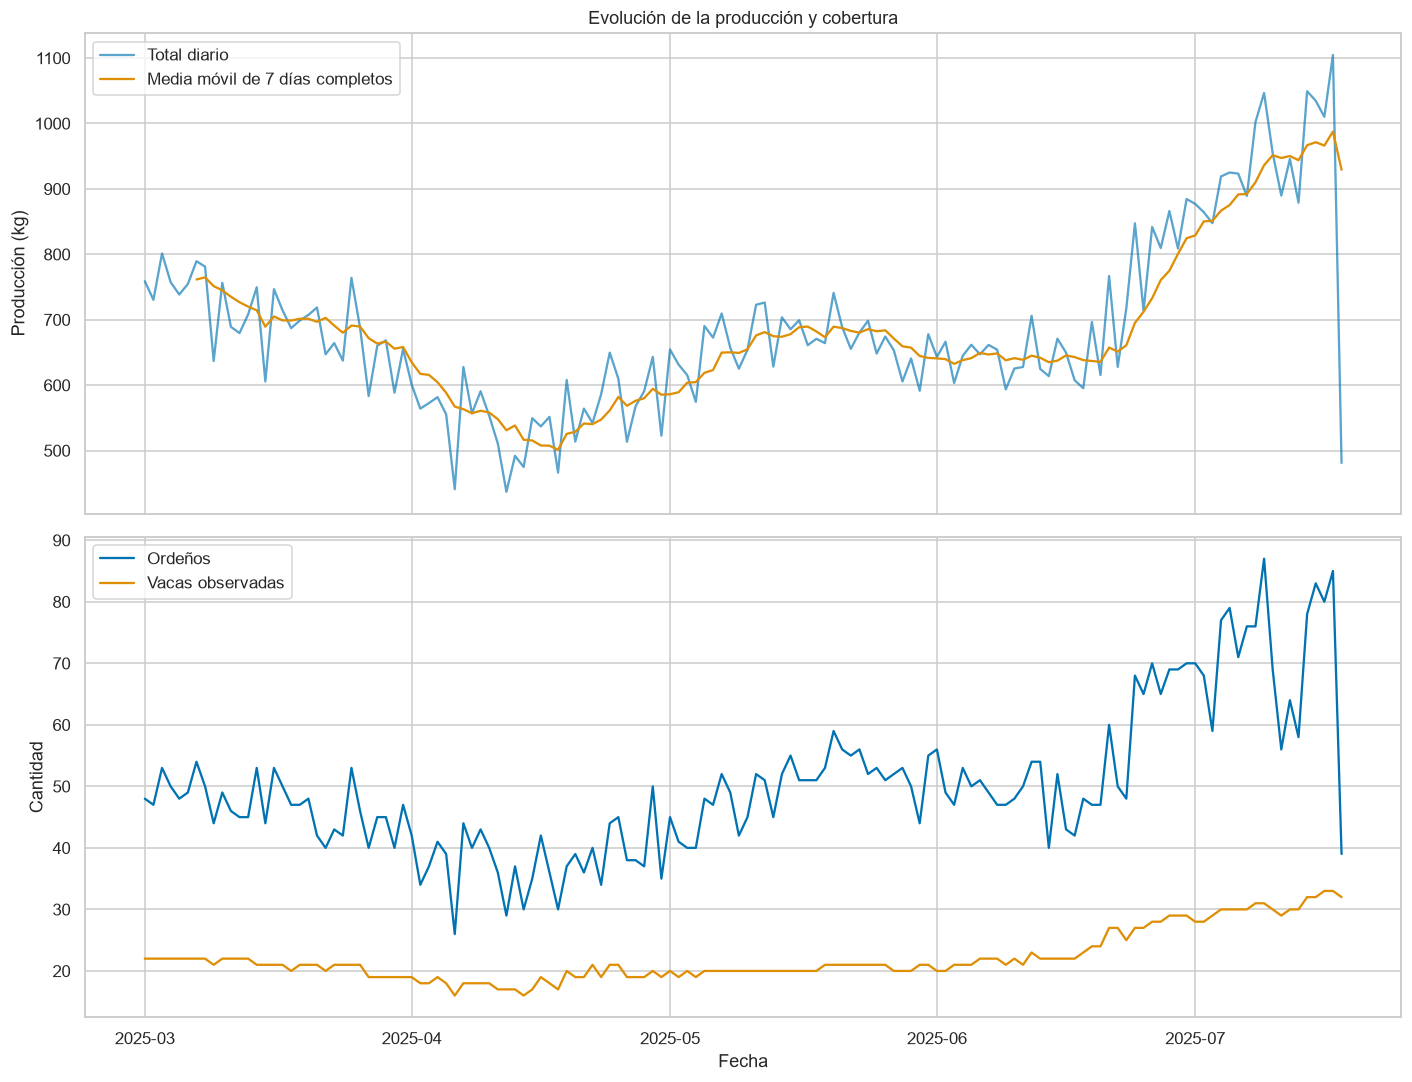

In [34]:
diario = ordenos.dropna(subset=["fecha"]).groupby("fecha").agg(
    produccion_total_kg=("main_produccion_kg", lambda s: s.sum(min_count=1)),
    produccion_media_kg=("main_produccion_kg", "mean"),
    ordenos=("id_vaca", "size"), vacas=("id_vaca", "nunique"))

calendario = pd.date_range(df.fecha.min(), df.fecha.max(), freq="D")
diario = diario.reindex(calendario)
diario.index.name = "fecha"
display(diario.describe().T)
print(f"Días sin eventos en el CSV: {len(calendario.difference(df.fecha.dropna().unique()))}")
print(f"Días sin ordeños: {diario.ordenos.isna().sum()}")

fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
axes[0].plot(diario.index, diario.produccion_total_kg, alpha=0.65, label="Total diario")
axes[0].plot(diario.index, diario.produccion_total_kg.rolling(7, min_periods=7).mean(),
             label="Media móvil de 7 días completos")
axes[0].set(ylabel="Producción (kg)", title="Evolución de la producción y cobertura")
axes[0].legend()
axes[1].plot(diario.index, diario.ordenos, label="Ordeños")
axes[1].plot(diario.index, diario.vacas, label="Vacas observadas")
axes[1].set(ylabel="Cantidad", xlabel="Fecha")
axes[1].legend()
plt.tight_layout()
plt.show()


En estas gráficas se puede observar la cantidad de producción, ordeños y vacas observadas en las fechas presentadas en nuestros datos.

Se observa una caida de producción entre el mes de abril-mayo, posteriormente vuelve a incrementar en los meses subsecuentes, aunque esto se puede complementar con la gráfica de ordeños donde se observa que en este mismo periodo de abril-mayo hubo un decremento en ordeños y en los meses siguientes volvió a incrementar, de aquí se espera que la relación es positiva entre estas dos variables, cuando una aumenta, también lo hará la otra. 

Además el número de vacas también parece seguir este mismo comportamiento, pudiendo ser la causa del porque se observa este patron, sin embargo esto no puede ser confirmado.

,ordenos,dias,media_kg,mediana_kg,total_kg,duracion_media_min
id_vaca,,,,,,
3ce7dd1a,275,115,18.846,18.980,"5,182.630",7.935
61af4174,246,89,18.625,18.355,"4,581.720",9.043
453b8961,250,81,17.982,17.430,"4,495.520",10.322
fe587085,102,54,17.000,17.385,"1,734.030",6.780
07802001,344,140,16.984,16.265,"5,842.630",7.257
0072065b,243,139,16.912,16.970,"4,109.550",8.011
5e57b4f1,269,140,16.399,17.360,"4,411.410",7.827
37248cfd,177,86,15.374,15.530,"2,721.150",6.966
7588fd14,419,140,14.962,14.730,"6,268.950",9.170


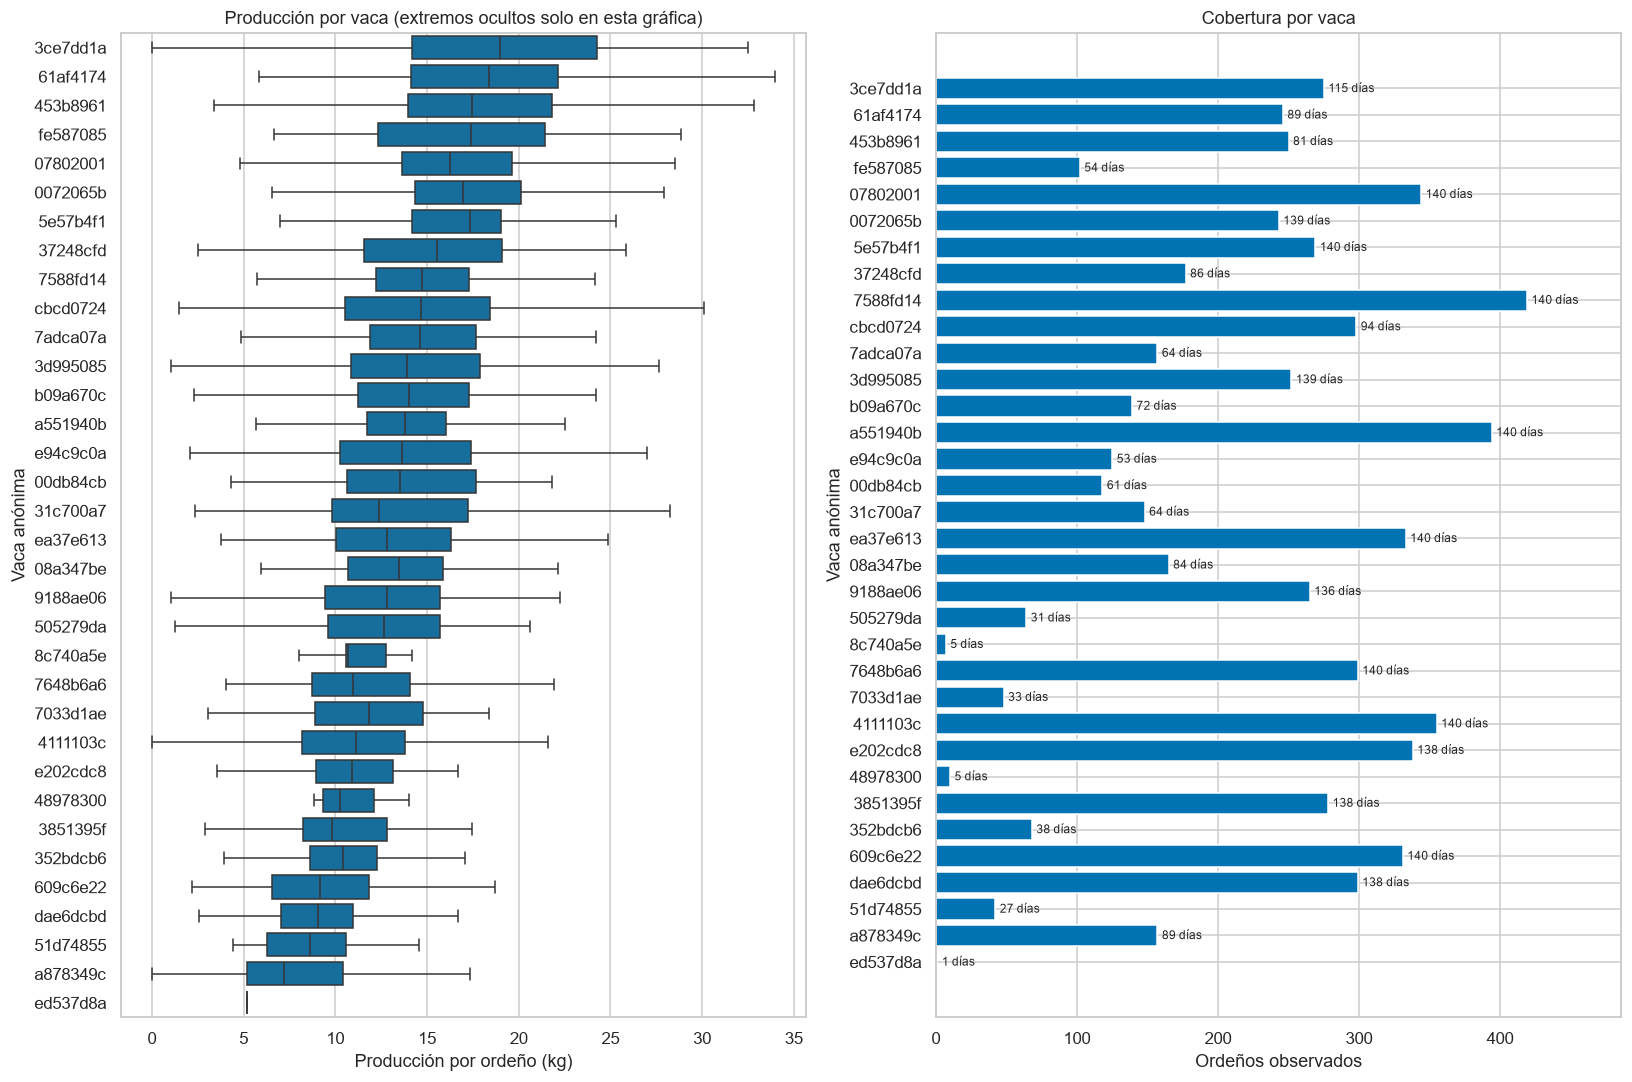

In [35]:
## Número de ordeños, días, producción media y mediana, producción total y duración media por vaca
por_vaca = ordenos.groupby("id_vaca").agg(
    ordenos=("main_produccion_kg", "count"), dias=("fecha", "nunique"),
    media_kg=("main_produccion_kg", "mean"), mediana_kg=("main_produccion_kg", "median"),
    total_kg=("main_produccion_kg", "sum"), duracion_media_min=("duracion_min", "mean"))
por_vaca = por_vaca.sort_values("media_kg", ascending=False)
display(por_vaca)

fig, axes = plt.subplots(1, 2, figsize=(15, 10))
sns.boxplot(data=ordenos, y="id_vaca", x="main_produccion_kg",
            order=por_vaca.index, showfliers=False, ax=axes[0])
axes[0].set(title="Producción por vaca (extremos ocultos solo en esta gráfica)",
            xlabel="Producción por ordeño (kg)", ylabel="Vaca anónima")
barras_cobertura = axes[1].barh(por_vaca.index, por_vaca.ordenos)
axes[1].bar_label(barras_cobertura, labels=[f"{dias} días" for dias in por_vaca.dias],
                  padding=3, fontsize=8)
axes[1].invert_yaxis()
axes[1].set(title="Cobertura por vaca", xlabel="Ordeños observados", ylabel="Vaca anónima",
            xlim=(0, por_vaca.ordenos.max() * 1.16))
plt.tight_layout()
plt.show()

La gráfica de la izquierda nos muestra la producción de cada una de las 34 vacas, el segmento en color azul corresponde al intervalo donde recae el 50% de los datos de producción observados para cada vaca, por ejemplo, para la primer vaca la mitad de sus datos reca entre 10 y 25 kg producidos aproximadamente.

La segunda gráfica nos muestra en el eje x el número de ordeños y en el eje y la vaca, siendo en conjunto la frecuencia individual de ordeño de cada vaca por día, podemos observar que existen vacas con el mismo número de días ordeñados pero con más ordeños en total. Además de que algunas vacas han acudido una poca cantidad de días, por ejemplo la última vaca solo ha ido un día y la vaca 49978300 5 días, etc. 

Por ello algunas vacas que aparentemente tengan poca producción o una producción menor que otras puede deberse a la cantidad de ordeños que tengan y la producción de cada uno de estos.

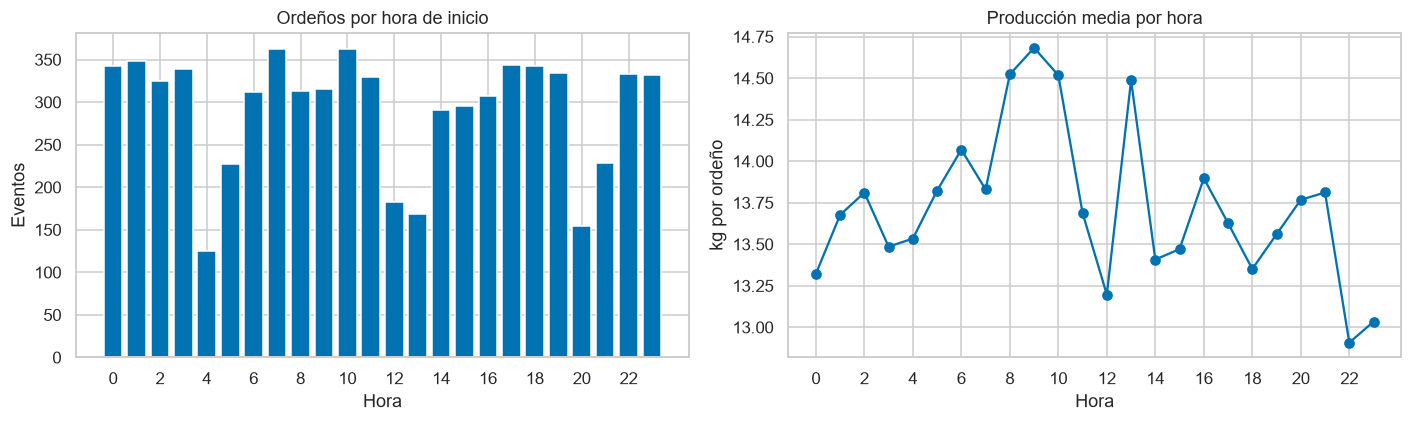

,eventos,vacas,dias,media_kg,mediana_kg
mes,,,,,
2025-03,1453,22,31,14.981,14.500
2025-04,1134,24,30,14.617,14.135
2025-05,1546,22,31,13.327,12.850
2025-06,1608,30,30,12.869,12.185
2025-07,1275,34,18,13.054,12.500


,eventos,vacas,media_kg
misc_eo_po,,,
7063e4b1,4134,34,13.340
86696b37,1615,8,15.088
b96e85be,1267,7,13.235


In [12]:
por_hora = ordenos.groupby("hora").agg(eventos=("id_vaca", "size"),
    media_kg=("main_produccion_kg", "mean")).reindex(range(24))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(por_hora.index, por_hora.eventos)
axes[0].set(title="Ordeños por hora de inicio", xlabel="Hora", ylabel="Eventos", xticks=range(0, 24, 2))
axes[1].plot(por_hora.index, por_hora.media_kg, marker="o")
axes[1].set(title="Producción media por hora", xlabel="Hora", ylabel="kg por ordeño", xticks=range(0, 24, 2))
plt.tight_layout()
plt.show()

mensual = ordenos.groupby("mes").agg(eventos=("id_vaca", "size"),
    vacas=("id_vaca", "nunique"), dias=("fecha", "nunique"),
    media_kg=("main_produccion_kg", "mean"), mediana_kg=("main_produccion_kg", "median"))
display(mensual)
display(ordenos.groupby("misc_eo_po").agg(eventos=("id_vaca", "size"),
    vacas=("id_vaca", "nunique"), media_kg=("main_produccion_kg", "mean")))

En la gráfica de la izquierda podemos ver los eventos en el eje y y las horas del día a la que ocurren (estas van en formato de 24 horas, de 0 - 23:59) se observa que a las 4 de la mañana, 12 del medio día y 8 de la noche (intervalos de 8 horas) hay una disminución en el número de ordeños, fuera de estos rangos, el número de ordeños parece constante, con algunas diferencias.

En la gráfica de la derecha se muestra la producción media por la hora del día, aquí si se observa un patron más claro donde el pico de producción promedio es alrededor de las 9 de la mañana, mientras que la producción desciende a de las 22:00 a 0:00 y a las 12 del mediodia .

En la primer tabla podemos observar el número de eventos, vacas y días que se consideraron en cuenta, así como la media y mediana de producción. Comp primera observación se puede ver que las medias y las medianas son muy parecidas, lo que era de esperarse ya que la distribución de la producción no presentaba colas tan marcadas que puedan inflar la media. Como segunda observación los eventos por mes parecen cercanos entre si, teniendo especiales caidas en los meses de abril y julio, este último puede explicarse por la baja cantidad de días registrados con datos.

En la última tabla se observa que tenemos 3 maquinas de ordeño, las cuales la mayoria de eventos ocurrieron en 7063e4b1 y todas las vacas estuvieron practicamente allí, ahora las otras dos maquinas de ordeño voluntario presentan menores eventos registrados y menores vacas, cuando se acudió al caetec nos comentaron que buscaban mantener los corrales lo más parecidos posibles, dejando uno para vacas con mayores comportamientos bullies, es posible que esto se implementara después del periodo de nuestros datos.

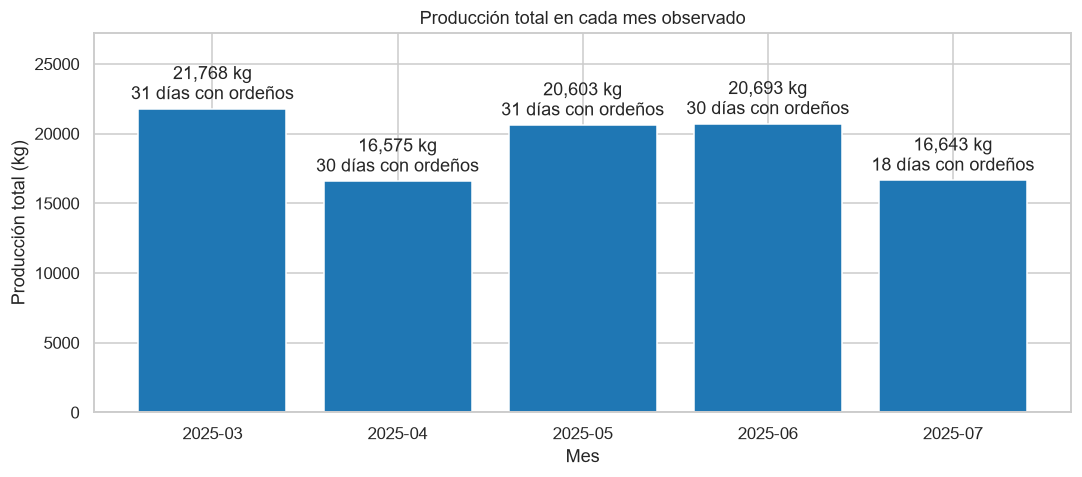

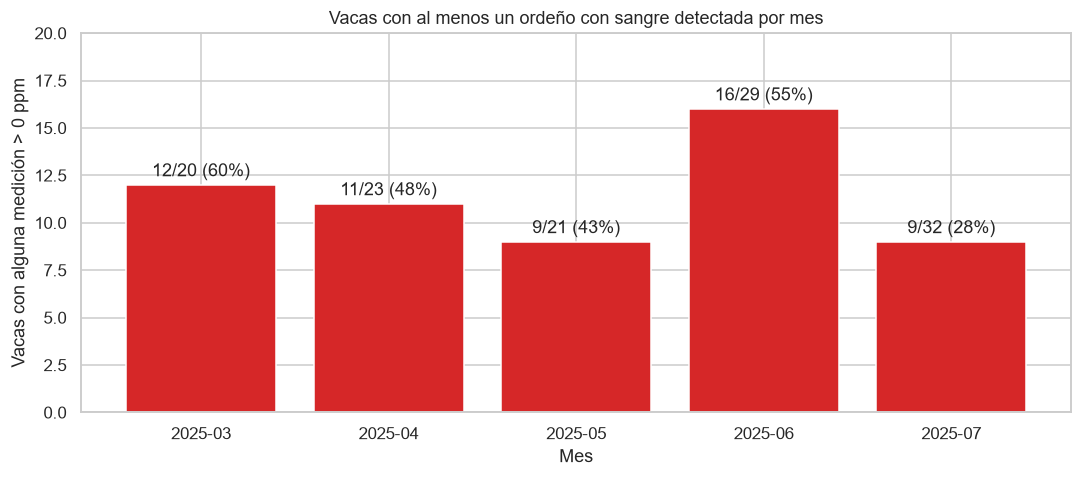

Etiquetas rojas: vacas con detección / vacas con cuatro mediciones disponibles (porcentaje).
Julio de 2025 es parcial; estos meses de un solo año no permiten concluir un patrón estacional.


In [29]:
# Comparación mensual: producción total y vacas con sangre detectada.
# Solo hay datos de marzo a julio de 2025; julio termina el día 18.
meses_observados = mensual.index.tolist()
produccion_total_mes = ordenos.groupby("mes")["main_produccion_kg"].sum(min_count=1).reindex(meses_observados)
dias_con_ordenos_mes = mensual["dias"].reindex(meses_observados)
fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.bar(meses_observados, produccion_total_mes, color="tab:blue")
ax.bar_label(barras, labels=[f"{total:,.0f} kg\n{dias} días con ordeños"
    for total, dias in zip(produccion_total_mes, dias_con_ordenos_mes)], padding=3)
ax.set(title="Producción total en cada mes observado",
       xlabel="Mes", ylabel="Producción total (kg)",
       ylim=(0, produccion_total_mes.max() * 1.25))
plt.tight_layout()
plt.show()

# Para contar vacas comparables se requieren mediciones de sangre en los cuatro cuartos.
columnas_sangre_mes = [f"sangre_ppm_{q}" for q in cuartos]
sangre_mes = ordenos.loc[ordenos[columnas_sangre_mes].notna().all(axis=1)].copy()
sangre_mes["sangre_detectada_mes"] = sangre_mes[columnas_sangre_mes].gt(0).any(axis=1)
vacas_evaluables_mes = sangre_mes.groupby("mes")["id_vaca"].nunique().reindex(meses_observados)
vacas_positivas_mes = (sangre_mes.loc[sangre_mes["sangre_detectada_mes"]]
    .groupby("mes")["id_vaca"].nunique().reindex(meses_observados, fill_value=0))
porcentaje_vacas_mes = vacas_positivas_mes.div(vacas_evaluables_mes).mul(100)
fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.bar(meses_observados, vacas_positivas_mes, color="tab:red")
ax.bar_label(barras, labels=[f"{positivas}/{total} ({porcentaje:.0f}%)"
    for positivas, total, porcentaje in zip(vacas_positivas_mes, vacas_evaluables_mes, porcentaje_vacas_mes)], padding=3)
ax.set(title="Vacas con al menos un ordeño con sangre detectada por mes",
       xlabel="Mes", ylabel="Vacas con alguna medición > 0 ppm",
       ylim=(0, vacas_positivas_mes.max() * 1.25))
plt.tight_layout()
plt.show()

print("Etiquetas rojas: vacas con detección / vacas con cuatro mediciones disponibles (porcentaje).")
print("Julio de 2025 es parcial; estos meses de un solo año no permiten concluir un patrón estacional.")

La primer grafica muestra la producción total en cada mes observado, adicionalmente del número de días con registros de ordeño que tuvo ese mes y la producción especifica en kg que hubo. 

La siguiente grafica muestra la cantidad de vacas que tuvieron al menos un ordeño con sangre por mes, en cada grafica al final podemos observar el número de vacas que presentaron sangre contra el número total de vacas y su porcentaje. Mientras que a primera vista podríamos pensar que el mes de junio tuvo más vacas que presentaron sangre en su ordeño y la realidad es que si, con 16 vacas es el mes que más vacas tuvo, pero en porcentaje el mes de marzo tuvo mayor cantidad de vacas con sangre que sanas. pese a esto es el mes que más leche producida tuvo en la muestra de datos que tenemos.

## 5. Correlaciones exploratorias

Se usa Spearman para describir asociaciones monotónicas. Cada coeficiente utiliza pares disponibles; por eso se muestra también su tamaño de muestra. Se excluyen identificadores y columnas completamente vacías. Las medidas por cuarto que componen la producción total pueden correlacionarse por construcción.

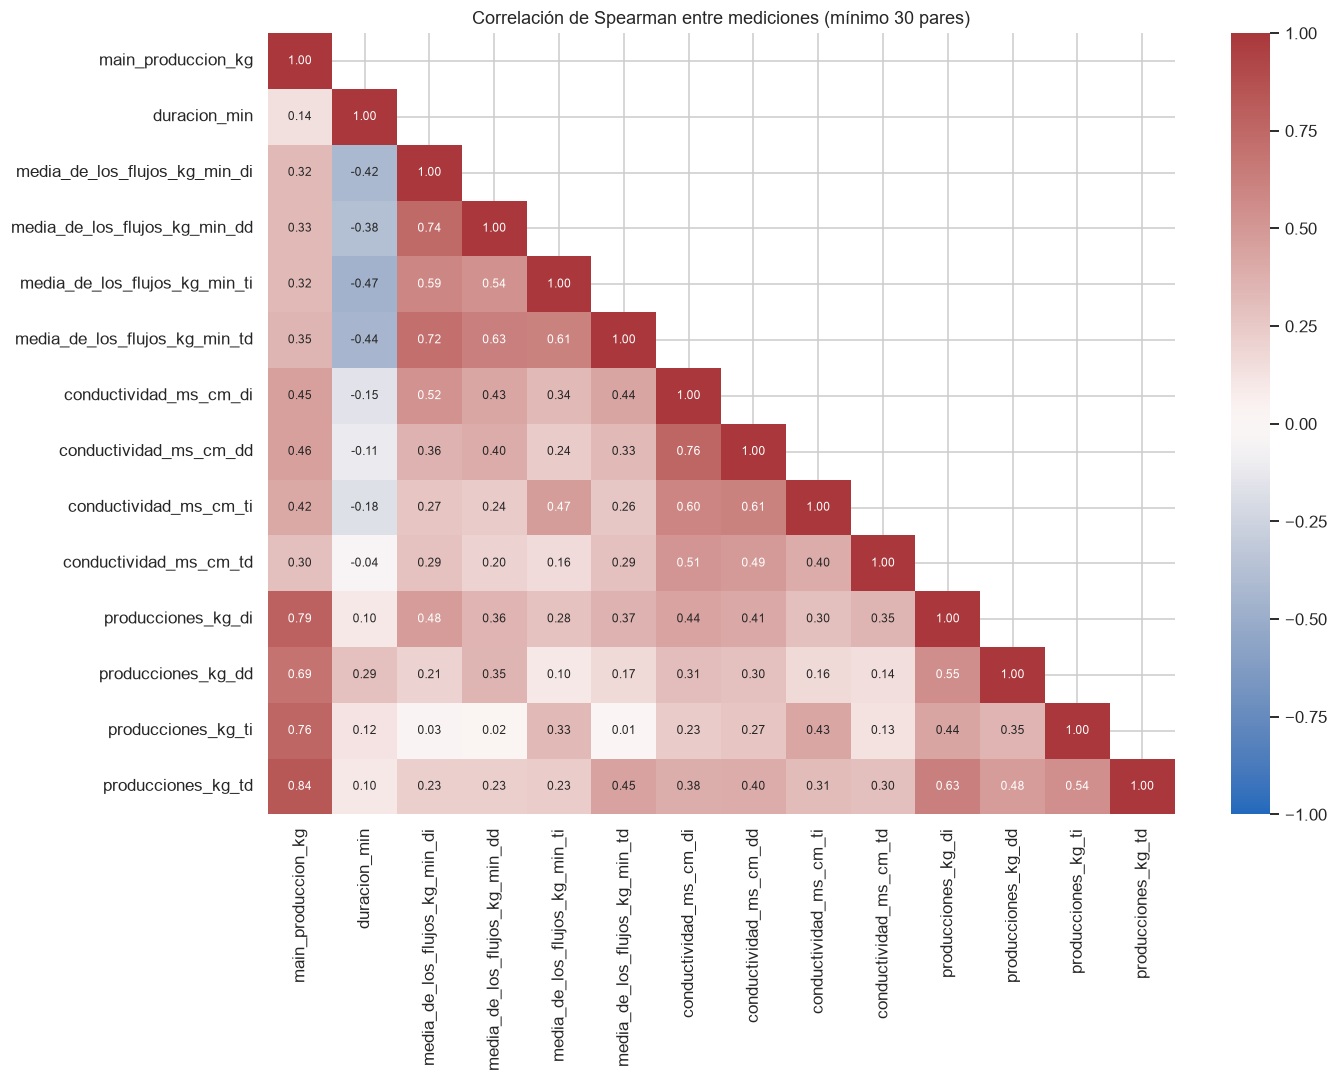

,spearman_con_produccion,pares_disponibles
producciones_kg_td,0.837,6952
producciones_kg_di,0.788,7016
producciones_kg_ti,0.760,6717
producciones_kg_dd,0.695,7013
conductividad_ms_cm_dd,0.456,7013
conductividad_ms_cm_di,0.454,7016
conductividad_ms_cm_ti,0.420,6717
media_de_los_flujos_kg_min_td,0.347,6952
media_de_los_flujos_kg_min_dd,0.334,7013
media_de_los_flujos_kg_min_ti,0.324,6717


In [15]:
variables = ["main_produccion_kg", "duracion_min"] + [f"media_de_los_flujos_kg_min_{q}" for q in cuartos] + [
    f"conductividad_ms_cm_{q}" for q in cuartos] + [f"producciones_kg_{q}" for q in cuartos]
correlacion = ordenos[variables].corr(method="spearman", min_periods=30)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(correlacion, mask=np.triu(np.ones_like(correlacion, dtype=bool), k=1),
            cmap="vlag", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax,
            annot_kws={"fontsize": 8})
ax.set_title("Correlación de Spearman entre mediciones (mínimo 30 pares)")
plt.tight_layout()
plt.show()
asociaciones = pd.DataFrame({
    "spearman_con_produccion": correlacion["main_produccion_kg"].drop("main_produccion_kg"),
    "pares_disponibles": {c: ordenos[["main_produccion_kg", c]].dropna().shape[0]
                         for c in variables if c != "main_produccion_kg"},
}).sort_values("spearman_con_produccion", key=lambda s: s.abs(), ascending=False)
display(asociaciones)

La relación más fuerte con la producción total aparece, como se esperaba, con las producciones de cada cuarto: TD tiene una correlación de Spearman de 0.84, DI de 0.79, TI de 0.76 y DD de 0.69. Esta relación tiene una explicación directa, ya que la producción total del ordeño se calcula a partir de la leche extraída de los cuartos. Por ello, estas correlaciones no deben interpretarse como variables independientes que predicen la producción total porque usar las producciones por cuarto para predecir el total del mismo ordeño produciría una relación circular. Las diferencias entre los coeficientes también pueden reflejar mediciones faltantes, ceros registrados o diferencias reales entre cuartos.

Las producciones de distintos cuartos también se relacionan positivamente; por ejemplo, DI con TD tiene ρ = 0.63. Una posible causa es que el nivel general de producción de una vaca, su etapa de lactancia, la alimentación o el tiempo transcurrido desde el ordeño afectan simultáneamente a varios cuartos. Esto no demuestra que un cuarto haga que otro produzca más, más bien ambos pueden responder a factores comunes que no están incluidos en la matriz.

Entre las correlaciones fuertes que no incluyen la producción total se encuentran las conductividades de DI y DD (ρ = 0.76), y los flujos medios de DI y DD (ρ = 0.74). También hay asociaciones de flujo entre otros pares de cuartos, entre 0.54 y 0.72. Es coherente que los cuatro cuartos compartan condiciones de la vaca, del equipo y del momento de extracción, además, variables medidas por la misma máquina pueden tener patrones comunes de calibración o de registro. Estas asociaciones pueden ser espurias si, por ejemplo, ciertas vacas o ciertos periodos concentran valores altos en todos sus cuartos.

La conductividad presenta una asociación moderada con la producción total, de aproximadamente 0.30 a 0.46 según el cuarto, y el flujo medio una asociación de aproximadamente 0.32 a 0.35. Estas relaciones indican que los valores tienden a variar en la misma dirección en parte de los ordeños, pero no son lo bastante fuertes para explicar por sí solas la producción. La duración tiene una relación débil con la producción total (ρ = 0.14): un ordeño más largo no implica necesariamente una producción mucho mayor, ya que la duración puede depender del flujo, incidencias, ajustes de la máquina o del procedimiento.